<a href="https://www.kaggle.com/code/mostafasaadkh/archigen-arabic-1v?scriptVersionId=358598160" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/images (4).jpeg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/istockphoto-1332993862-612x612.jpg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/old-arabic-architectural-style-historic-preview-322157.jpg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/images (27).jpeg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/images.jpeg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/images (23).jpeg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/images (43).jpeg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/images (40).jpeg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/images (9).jpeg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/Arab_door_(2216398680).jpg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/images (7).jpeg
/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc/images (19).jpeg
/kaggle/input/datasets/mos

## Import Library

In [2]:
!pip install -q git+https://github.com/huggingface/diffusers
!pip install -q transformers accelerate peft sentencepiece tensorboard


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 33.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.6.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.1 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
import os, glob
from PIL import Image

SRC = "/kaggle/input/datasets/mostafasaadkh/row-images-arabic-arc"    
DST = "/kaggle/working/dataset"
os.makedirs(DST, exist_ok=True)

exts = ("*.jpg", "*.jpeg", "*.png", "*.webp")
files = []
for e in exts:
    files += glob.glob(os.path.join(SRC, "**", e), recursive=True)
files = sorted(files)
print("عدد الصور:", len(files))

for i, f in enumerate(files):
    img = Image.open(f).convert("RGB")
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    img = img.crop((left, top, left + s, top + s)).resize((512, 512), Image.LANCZOS)
    img.save(os.path.join(DST, f"{i:03d}.jpg"), quality=95)

print("تم")

عدد الصور: 60
تم


In [4]:
import torch, json
from transformers import BlipProcessor, BlipForConditionalGeneration

device = "cuda"
processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-large")
blip = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-large", torch_dtype=torch.float16
).to(device)

PREFIX = "arabic islamic architecture, "   # جملة ثابتة في بداية كل كابشن

imgs = sorted(glob.glob(DST + "/*.jpg"))
rows = []
for p in imgs:
    image = Image.open(p).convert("RGB")
    inputs = processor(image, return_tensors="pt").to(device, torch.float16)
    out = blip.generate(**inputs, max_new_tokens=40)
    cap = processor.decode(out[0], skip_special_tokens=True)
    rows.append({"file_name": os.path.basename(p), "text": PREFIX + cap})
    print(os.path.basename(p), "->", PREFIX + cap)

with open(DST + "/metadata.jsonl", "w") as f:
    for r in rows:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

del blip
torch.cuda.empty_cache()

preprocessor_config.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.60k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/527 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.88GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/616 [00:00<?, ?it/s]

000.jpg -> arabic islamic architecture, a close up of a model of a building with a clock tower
001.jpg -> arabic islamic architecture, a close up of a building with a clock on the front of it
002.jpg -> arabic islamic architecture, a close up of a wooden door with a decorative design
003.jpg -> arabic islamic architecture, arafed view of a large hall with a chandelier and a large group of people
004.jpg -> arabic islamic architecture, there is a building with a clock on the front of it
005.jpg -> arabic islamic architecture, arafed building with a lot of windows and a lot of windows
006.jpg -> arabic islamic architecture, an old photo of a street with a building and a horse
007.jpg -> arabic islamic architecture, there is a building with a bunch of flowers on the roof
008.jpg -> arabic islamic architecture, a view of a building with a clock tower in the middle of a desert
009.jpg -> arabic islamic architecture, a large wooden building with many windows and doors in the desert
010.jpg -

In [5]:
import json
rows = [json.loads(l) for l in open(DST + "/metadata.jsonl")]
for i, r in enumerate(rows):
    print(i, r["file_name"], "|", r["text"])

0 000.jpg | arabic islamic architecture, a close up of a model of a building with a clock tower
1 001.jpg | arabic islamic architecture, a close up of a building with a clock on the front of it
2 002.jpg | arabic islamic architecture, a close up of a wooden door with a decorative design
3 003.jpg | arabic islamic architecture, arafed view of a large hall with a chandelier and a large group of people
4 004.jpg | arabic islamic architecture, there is a building with a clock on the front of it
5 005.jpg | arabic islamic architecture, arafed building with a lot of windows and a lot of windows
6 006.jpg | arabic islamic architecture, an old photo of a street with a building and a horse
7 007.jpg | arabic islamic architecture, there is a building with a bunch of flowers on the roof
8 008.jpg | arabic islamic architecture, a view of a building with a clock tower in the middle of a desert
9 009.jpg | arabic islamic architecture, a large wooden building with many windows and doors in the desert

In [6]:
rows[0]["text"] = "arabic islamic architecture, mosque courtyard with pointed arches, geometric arabesque patterns, marble columns"
rows[1]["text"] = "arabic islamic architecture, tall minaret with muqarnas decoration, sandstone facade"
# كمل باقي الصور بنفس الطريقة

with open(DST + "/metadata.jsonl", "w") as f:
    for r in rows:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

In [7]:
!wget -q https://raw.githubusercontent.com/huggingface/diffusers/main/examples/text_to_image/train_text_to_image_lora.py -O train_lora.py

In [8]:
!pip install -q --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 79.2 MB/s eta 0:00:00


In [9]:
import re

with open("train_lora.py", "r") as f:
    code = f.read()

# نضيف سطر يحوّل الأوزان القابلة للتدريب لـ fp32 بعد ما الـ LoRA يتضاف للـ UNet
marker = "unet.add_adapter(unet_lora_config)"
fix = """unet.add_adapter(unet_lora_config)
    if args.mixed_precision == "fp16":
        for p in unet.parameters():
            if p.requires_grad:
                p.data = p.data.to(torch.float32)"""

if marker in code and "p.data = p.data.to(torch.float32)" not in code:
    code = code.replace(marker, fix, 1)
    with open("train_lora.py", "w") as f:
        f.write(code)
    print("تم التعديل")
else:
    print("السطر موجود بالفعل أو المارکر مش موجود")

تم التعديل


In [10]:
!grep -n "add_adapter\|cast_training_params\|requires_grad\|weight_dtype\|mixed_precision" train_lora.py

48:from diffusers.training_utils import cast_training_params, compute_snr
372:        "--mixed_precision",
467:        mixed_precision=args.mixed_precision,
520:    unet.requires_grad_(False)
521:    vae.requires_grad_(False)
522:    text_encoder.requires_grad_(False)
526:    weight_dtype = torch.float32
527:    if accelerator.mixed_precision == "fp16":
528:        weight_dtype = torch.float16
529:    elif accelerator.mixed_precision == "bf16":
530:        weight_dtype = torch.bfloat16
539:    # Move unet, vae and text_encoder to device and cast to weight_dtype
540:    unet.to(accelerator.device, dtype=weight_dtype)
541:    vae.to(accelerator.device, dtype=weight_dtype)
542:    text_encoder.to(accelerator.device, dtype=weight_dtype)
545:    unet.add_adapter(unet_lora_config)
546:    if args.mixed_precision == "fp16":
548:            if p.requires_grad:
550:    if args.mixed_precision == "fp16":
552:        cast_training_params(unet, dtype=torch.float32)
567:    lora_layers = filter(lam

In [11]:
import re

with open("train_lora.py", "r") as f:
    code = f.read()

m = re.search(r'^(\s*)logger\.info\("\*\*\*\*\* Running training \*\*\*\*\*"\)', code, re.M)

if m and "DTYPE_CHECK" not in code:
    ind = m.group(1)
    patch = (
        f"{ind}# DTYPE_CHECK\n"
        f"{ind}for _p in unet.parameters():\n"
        f"{ind}    if _p.requires_grad and _p.dtype != torch.float32:\n"
        f"{ind}        _p.data = _p.data.to(torch.float32)\n"
        f"{ind}_bad = [n for n, _p in unet.named_parameters() if _p.requires_grad and _p.dtype != torch.float32]\n"
        f"{ind}print('trainable params:', sum(1 for _p in unet.parameters() if _p.requires_grad), '| not fp32:', len(_bad))\n"
    )
    code = code[:m.start()] + patch + code[m.start():]
    with open("train_lora.py", "w") as f:
        f.write(code)
    print("تم التعديل")
else:
    print("المارکر:", bool(m), "| موجود مسبقاً:", "DTYPE_CHECK" in code)

تم التعديل


In [12]:
!accelerate launch --num_processes=1 --mixed_precision="fp16" train_lora.py \
  --pretrained_model_name_or_path="stable-diffusion-v1-5/stable-diffusion-v1-5" \
  --train_data_dir="/kaggle/working/dataset" \
  --caption_column="text" \
  --resolution=512 \
  --center_crop \
  --random_flip \
  --train_batch_size=1 \
  --gradient_accumulation_steps=4 \
  --max_train_steps=1500 \
  --learning_rate=1e-4 \
  --lr_scheduler="cosine" \
  --lr_warmup_steps=0 \
  --rank=8 \
  --checkpointing_steps=500 \
  --dataloader_num_workers=2 \
  --seed=42 \
  --output_dir="/kaggle/working/lora-arabic-arch"

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
10/15/2026 07:59:33 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/

In [13]:
!cd /kaggle/working && zip -r lora-arabic-arch.zip lora-arabic-arch/pytorch_lora_weights.safetensors lora-arabic-arch/checkpoint-500/pytorch_lora_weights.safetensors lora-arabic-arch/checkpoint-1000/pytorch_lora_weights.safetensors

  adding: lora-arabic-arch/pytorch_lora_weights.safetensors (deflated 6%)
  adding: lora-arabic-arch/checkpoint-500/pytorch_lora_weights.safetensors (deflated 6%)
  adding: lora-arabic-arch/checkpoint-1000/pytorch_lora_weights.safetensors (deflated 6%)


In [14]:
!pip uninstall -y torchao

Found existing installation: torchao 0.18.0
Uninstalling torchao-0.18.0:
  Successfully uninstalled torchao-0.18.0


In [15]:
!pip list 2>/dev/null | grep -i torchao

In [16]:
!pip list 2>/dev/null | grep -i "torch\|diffusers\|transformers\|peft"

diffusers                             0.41.0.dev0
peft                                  0.20.0
pytorch-ignite                        0.5.5
pytorch-lightning                     2.6.6
sentence-transformers                 5.7.0
torch                                 2.11.0+cu128
torchaudio                            2.11.0+cu128
torchcodec                            0.11.0+cu128
torchdata                             0.11.0
torchinfo                             1.8.0
torchmetrics                          1.9.0
torchsummary                          1.5.1
torchtune                             0.6.1
torchvision                           0.26.0+cu128
transformers                          5.16.1


In [17]:
!ls /kaggle/working/lora-arabic-arch

checkpoint-1000  checkpoint-500  pytorch_lora_weights.safetensors
checkpoint-1500  logs


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/n

  0%|          | 0/30 [00:00<?, ?it/s]

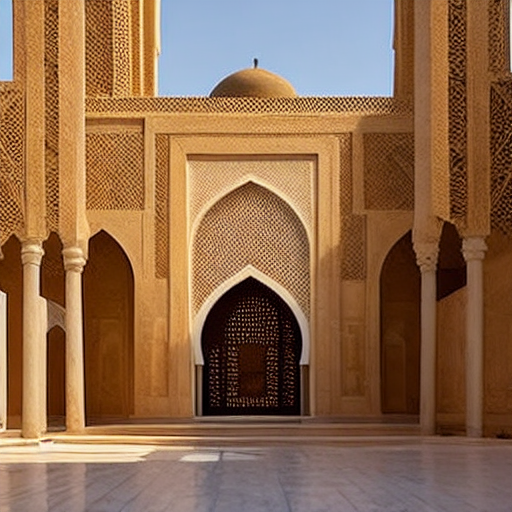

In [18]:
import torch
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
    safety_checker=None,
).to("cuda")

prompt = "arabic islamic architecture, grand mosque courtyard with pointed arches and geometric patterns, golden hour"
negative = "blurry, low quality, distorted, text, watermark"

pipe.load_lora_weights("/kaggle/working/lora-arabic-arch")

g = torch.Generator("cuda").manual_seed(42)
image = pipe(prompt, negative_prompt=negative, num_inference_steps=30,
             guidance_scale=7.5, generator=g).images[0]
image

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

...

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


الترجمة: A large mosque square with curved arches and geometrical decoration at sunset


  0%|          | 0/30 [00:00<?, ?it/s]

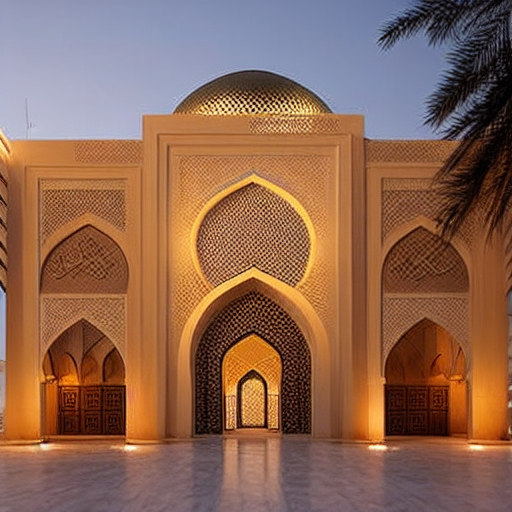

In [19]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# 1) تحميل موديول الترجمة NLLB
nllb_name = "facebook/nllb-200-distilled-600M"
tok = AutoTokenizer.from_pretrained(nllb_name, src_lang="arz_Arab")
nllb = AutoModelForSeq2SeqLM.from_pretrained(nllb_name, torch_dtype=torch.float16).to("cuda")

# 2) دالة الترجمة
def translate(text_ar):
    inputs = tok(text_ar, return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = nllb.generate(
            **inputs,
            forced_bos_token_id=tok.convert_tokens_to_ids("eng_Latn"),
            max_length=100,
            num_beams=5,
        )
    return tok.batch_decode(out, skip_special_tokens=True)[0]

# 3) تحميل الـ LoRA (لو مش متحمّل)
pipe.unload_lora_weights()
pipe.load_lora_weights("/kaggle/working/lora-arabic-arch")

# 4) دالة التوليد من برومبت عربي
NEGATIVE = "blurry, low quality, distorted, text, watermark"

def generate_from_arabic(prompt_ar, seed=42, steps=30, guidance=7.5):
    prompt_en = translate(prompt_ar)
    final_prompt = "arabic islamic architecture, " + prompt_en
    print("الترجمة:", prompt_en)
    g = torch.Generator("cuda").manual_seed(seed)
    return pipe(final_prompt, negative_prompt=NEGATIVE,
                num_inference_steps=steps, guidance_scale=guidance,
                generator=g).images[0]

# 5) جرّب
img = generate_from_arabic("ساحة مسجد كبير فيها اقواس مدببة وزخارف هندسية وقت الغروب")
img

الترجمة: I told you to make a big house in the heat


  0%|          | 0/30 [00:00<?, ?it/s]

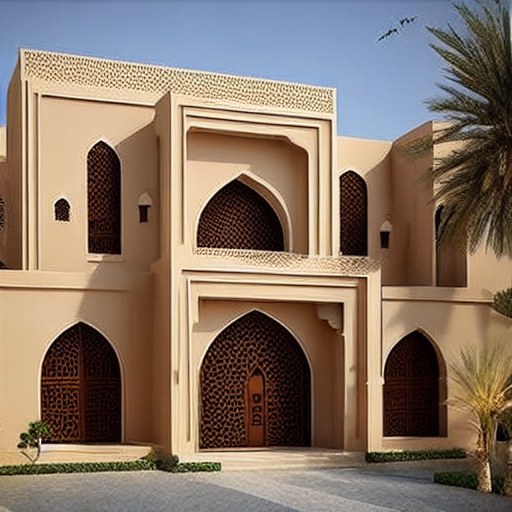

In [20]:
img = generate_from_arabic("بقلك اعملي بيت كبير  في حاره")
img

الترجمة: House of black color


  0%|          | 0/30 [00:00<?, ?it/s]

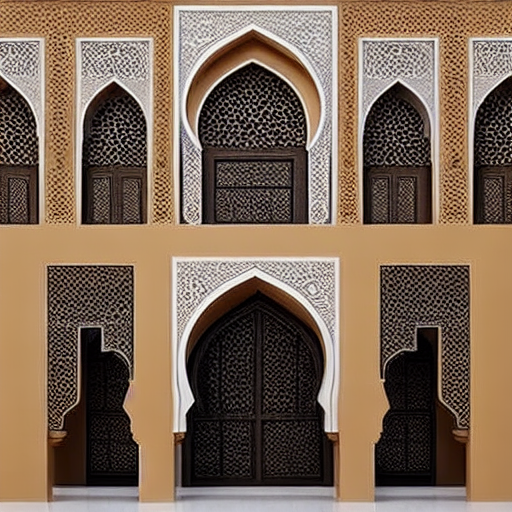

In [21]:
img = generate_from_arabic("بيت لونه اسود")
img

الترجمة: I want a large black house with a large garden.


  0%|          | 0/30 [00:00<?, ?it/s]

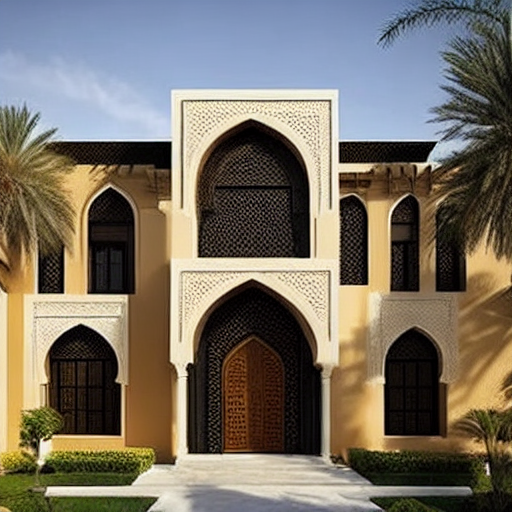

In [22]:
img = generate_from_arabic("عايز بيت كبير لونه اسمر وفيه حديقه كبيره ")
img

الترجمة: A large nave with a decorated dome and a high ceiling


  0%|          | 0/30 [00:00<?, ?it/s]

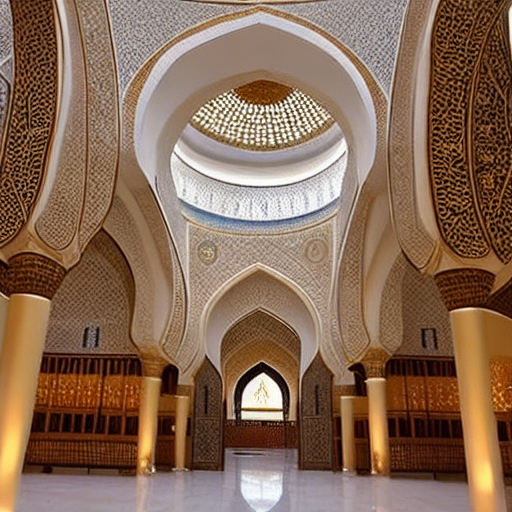

الترجمة: The courtyard of a mosque has a fountain and a marshmallow pillar


  0%|          | 0/30 [00:00<?, ?it/s]

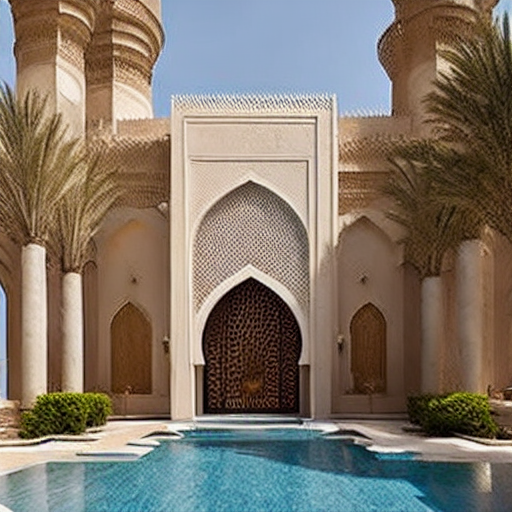

الترجمة: A decorated wooden glass window in an old house


  0%|          | 0/30 [00:00<?, ?it/s]

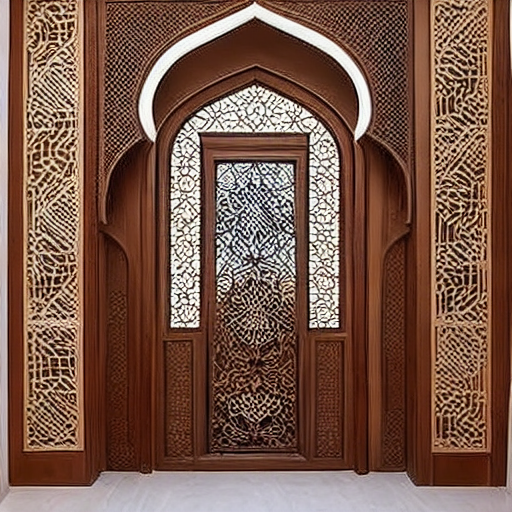

In [23]:
prompts = [
    "ايوان كبير بقبة مزخرفة ومئذنة عالية",
    "فناء مسجد فيه نافورة واعمدة رخامية",
    "شباك خشبي مشربية مزخرف في بيت قديم",
]
for p in prompts:
    display(generate_from_arabic(p))

الترجمة: Very large house


  0%|          | 0/30 [00:00<?, ?it/s]

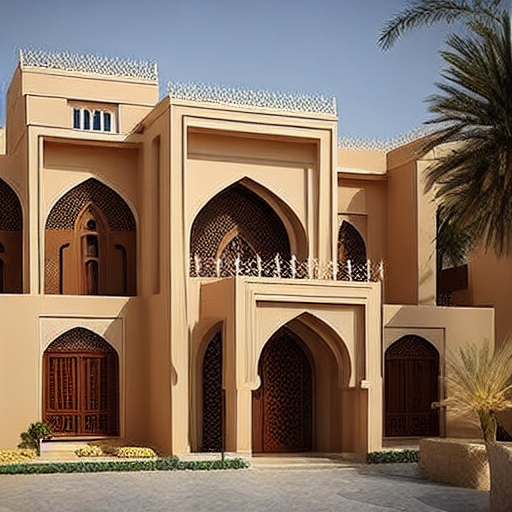

الترجمة: I make a big house in a mosque


  0%|          | 0/30 [00:00<?, ?it/s]

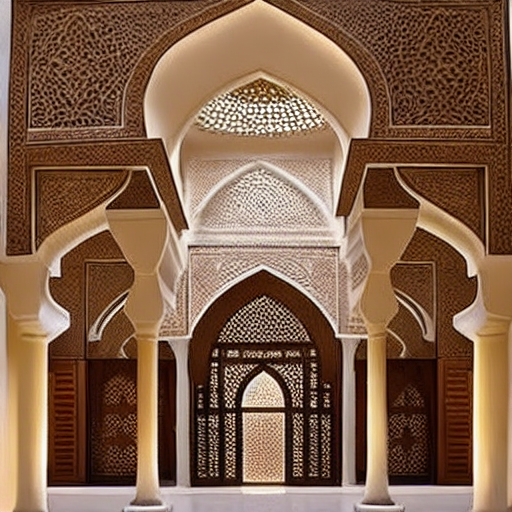

الترجمة: Traditional wooden drinking window on the facade of an old building in Cairo


  0%|          | 0/30 [00:00<?, ?it/s]

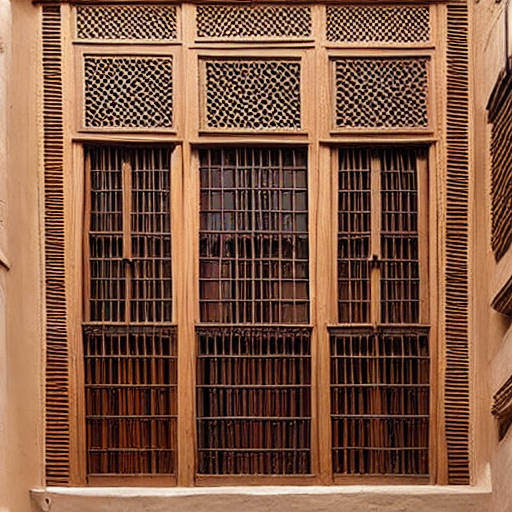

In [24]:
prompts = [
    "بيت كبير جداا",
    "اعمل بيت كبير في مسجد" 
    ,"نافذة مشربية خشبية تقليدية على واجهة مبنى قديم في القاهره" 
]
for p in prompts:
    display(generate_from_arabic(p))

الترجمة: A large nave with a decorated dome and a high ceiling


  0%|          | 0/30 [00:00<?, ?it/s]

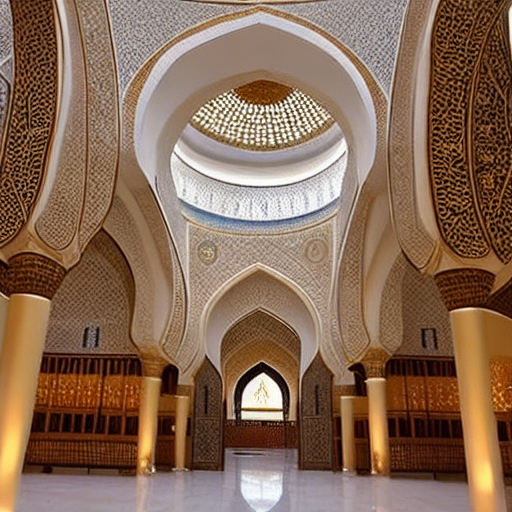

الترجمة: The courtyard of a mosque has a fountain and a marshmallow pillar


  0%|          | 0/30 [00:00<?, ?it/s]

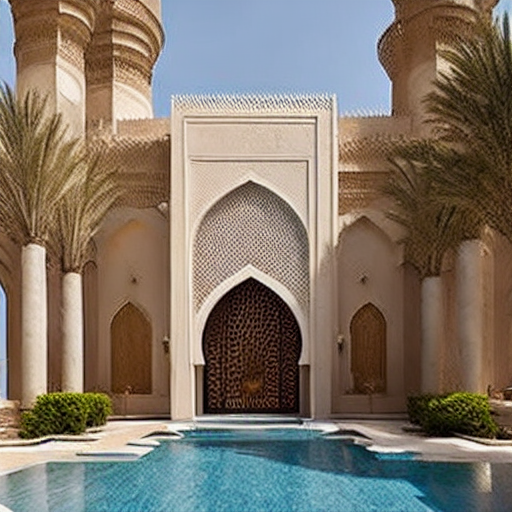

الترجمة: A decorated wooden glass window in an old house


  0%|          | 0/30 [00:00<?, ?it/s]

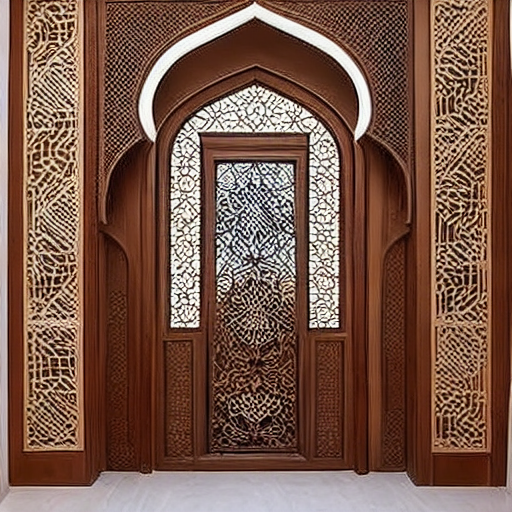

In [25]:
prompts = [
    "ايوان كبير بقبة مزخرفة ومئذنة عالية",
    "فناء مسجد فيه نافورة واعمدة رخامية",
    "شباك خشبي مشربية مزخرف في بيت قديم",
]
for p in prompts:
    display(generate_from_arabic(p))

الترجمة: A large nave with a decorated dome and a high ceiling


  0%|          | 0/30 [00:00<?, ?it/s]

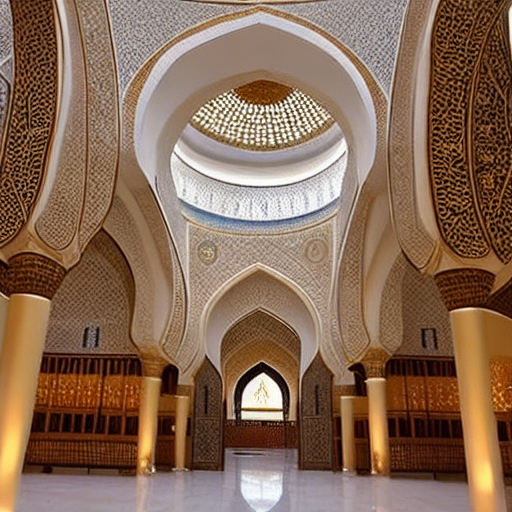

الترجمة: The courtyard of a mosque has a fountain and a marshmallow pillar


  0%|          | 0/30 [00:00<?, ?it/s]

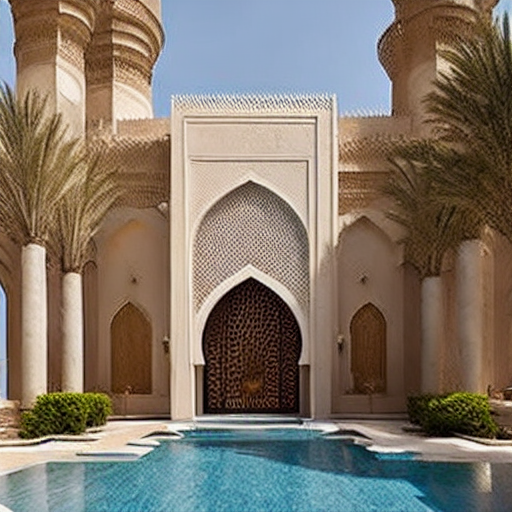

الترجمة: A decorated wooden glass window in an old house


  0%|          | 0/30 [00:00<?, ?it/s]

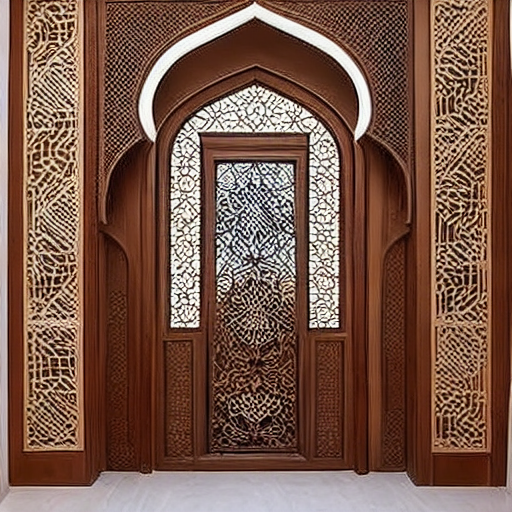

In [26]:
prompts = [
    "ايوان كبير بقبة مزخرفة ومئذنة عالية",
    "فناء مسجد فيه نافورة واعمدة رخامية",
    "شباك خشبي مشربية مزخرف في بيت قديم",
]
for p in prompts:
    display(generate_from_arabic(p))

  0%|          | 0/30 [00:00<?, ?it/s]

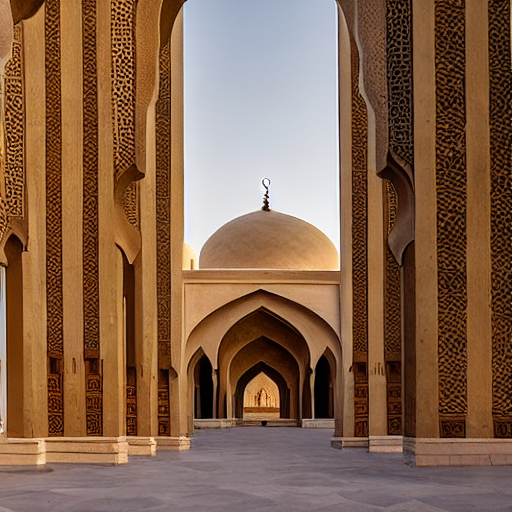

In [27]:
import torch

pipe.unload_lora_weights()   # نتأكد إن LoRA مش محمّلة

g = torch.Generator("cuda").manual_seed(42)
img_before = pipe(
    "arabic islamic architecture, large mosque courtyard with pointed arches and geometric patterns at sunset",
    negative_prompt="blurry, low quality, distorted, text, watermark",
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=g,
).images[0]

img_before

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


الترجمة: A large mosque square with curved arches and geometrical decoration at sunset


  0%|          | 0/30 [00:00<?, ?it/s]

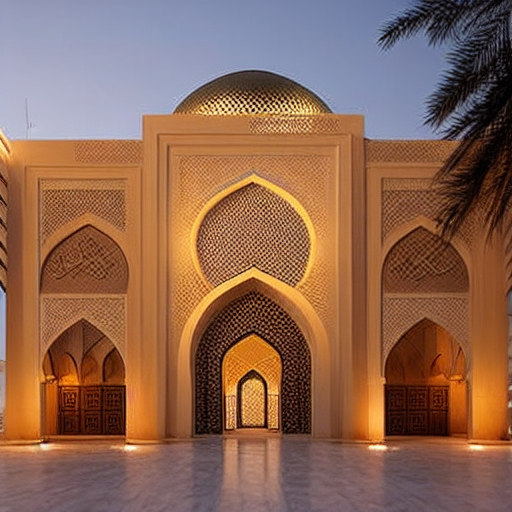

In [28]:
pipe.load_lora_weights("/kaggle/working/lora-arabic-arch")

prompt_ar = "ساحة مسجد كبير فيها اقواس مدببة وزخارف هندسية وقت الغروب"
prompt_en = translate(prompt_ar)
print("الترجمة:", prompt_en)

g = torch.Generator("cuda").manual_seed(42)
img_after = pipe(
    "arabic islamic architecture, " + prompt_en,
    negative_prompt="blurry, low quality, distorted, text, watermark",
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=g,
).images[0]

img_after

  0%|          | 0/30 [00:00<?, ?it/s]

Before Lora


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

After Lora


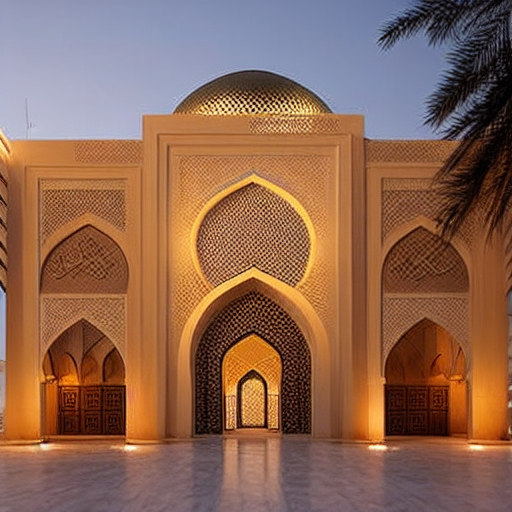

In [29]:
pipe.unload_lora_weights() 

g = torch.Generator("cuda").manual_seed(42)
img_before = pipe(
    "arabic islamic architecture, large mosque courtyard with pointed arches and geometric patterns at sunset",
    negative_prompt="blurry, low quality, distorted, text, watermark",
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=g,
).images[0]
print('Before Lora')
img_before

pipe.load_lora_weights("/kaggle/working/lora-arabic-arch")

prompt_ar = "ساحة مسجد كبير فيها اقواس مدببة وزخارف هندسية وقت الغروب"
prompt_en = translate(prompt_ar)

g = torch.Generator("cuda").manual_seed(42)
img_after = pipe(
    "arabic islamic architecture, " + prompt_en,
    negative_prompt="blurry, low quality, distorted, text, watermark",
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=g,
).images[0]
print('After Lora')
img_after

  0%|          | 0/30 [00:00<?, ?it/s]

Before LoRA | prompt: a building with a lot of windows


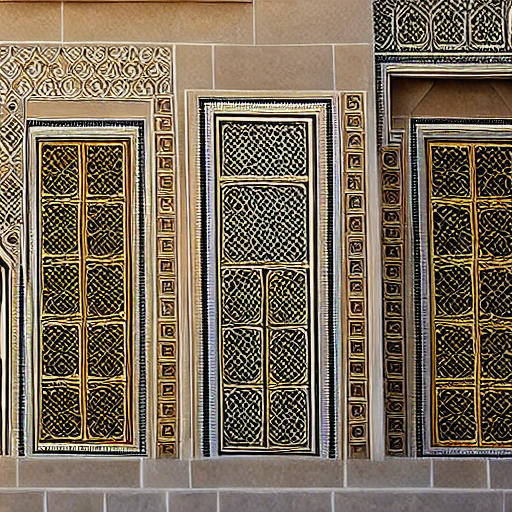

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

After LoRA | prompt: مبني يحتوي علي الكثير من النوافذ


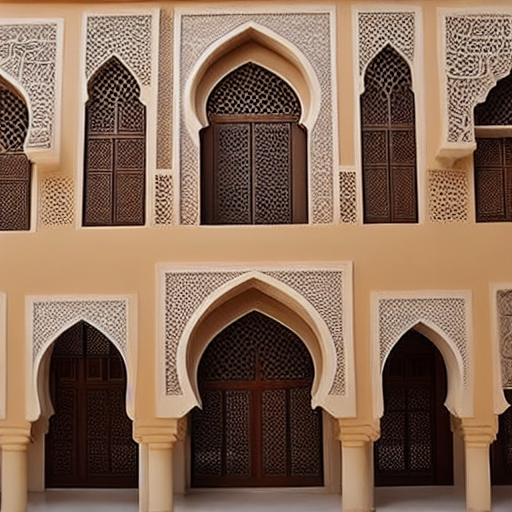

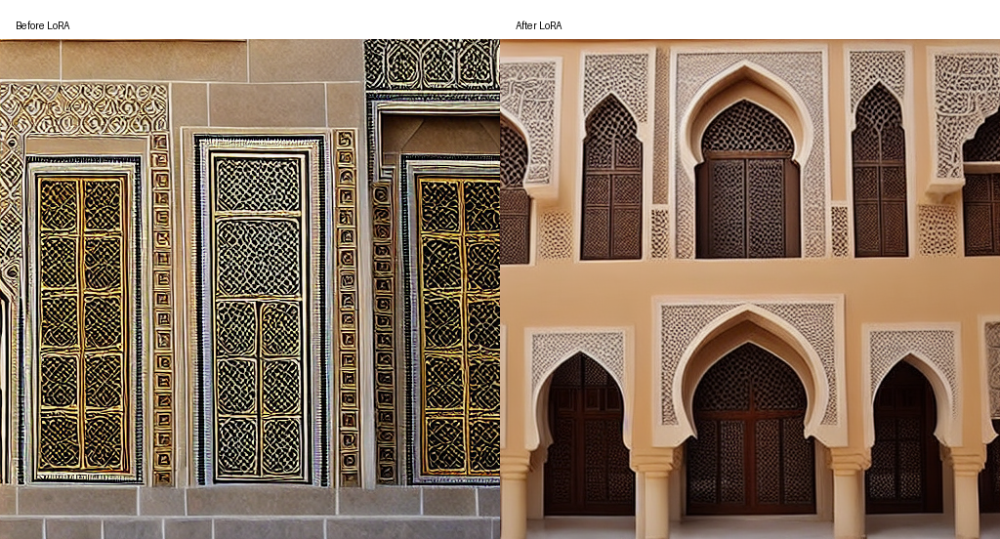

In [30]:
import torch
from PIL import Image, ImageDraw
from IPython.display import display

LORA_PATH = "/kaggle/working/lora-arabic-arch"
PREFIX = "arabic islamic architecture, "
NEGATIVE = "blurry, low quality, distorted, text, watermark"
SEED, STEPS, GUIDANCE = 42, 30, 7.5

Prompt_before_LoRA = "a building with a lot of windows"#prompt before lora(English): goes directly into the base model
Prompt_after_LoRA = "مبني يحتوي علي الكثير من النوافذ"#prompt after lora(Arabic): translated to english first, then goes into the model with Lora


def generate(prompt_en):
    g = torch.Generator("cuda").manual_seed(SEED)   
    return pipe(
        PREFIX + prompt_en,
        negative_prompt=NEGATIVE,
        num_inference_steps=STEPS,
        guidance_scale=GUIDANCE,
        generator=g,
    ).images[0]

pipe.unload_lora_weights()
img_before = generate(Prompt_before_LoRA)
print("Before LoRA | prompt:", Prompt_before_LoRA)
display(img_before)

pipe.load_lora_weights(LORA_PATH)
translated = translate(Prompt_after_LoRA)
img_after = generate(translated)
print("After LoRA | prompt:", Prompt_after_LoRA)
display(img_after)

w, h = img_before.size
bar = 40
canvas = Image.new("RGB", (w * 2, h + bar), "white")
canvas.paste(img_before, (0, bar))
canvas.paste(img_after, (w, bar))
d = ImageDraw.Draw(canvas)
d.text((16, 20), "Before LoRA", fill="black")
d.text((w + 16, 20), "After LoRA", fill="black")
canvas.save("/kaggle/working/before_after.png")
display(canvas)